In [177]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [178]:
df = pd.read_csv('../raw_data/airlines_flights_data.csv',index_col='index')

df.shape

(300153, 11)

In [179]:
df.head()

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
index,,,,,,,,,,,
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [180]:
df.tail()

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
index,,,,,,,,,,,
300148,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,69265
300149,Vistara,UK-826,Chennai,Afternoon,one,Night,Hyderabad,Business,10.42,49,77105
300150,Vistara,UK-832,Chennai,Early_Morning,one,Night,Hyderabad,Business,13.83,49,79099
300151,Vistara,UK-828,Chennai,Early_Morning,one,Evening,Hyderabad,Business,10.00,49,81585
300152,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,81585


In [181]:
for dtypes,cols in df.dtypes.groupby(df.dtypes.astype(str)).groups.items():
    print(f'{dtypes} : {cols} \n')


float64 : Index(['duration'], dtype='str') 

int64 : Index(['days_left', 'price'], dtype='str') 

str : Index(['airline', 'flight', 'source_city', 'departure_time', 'stops',
       'arrival_time', 'destination_city', 'class'],
      dtype='str') 



In [182]:
df.describe()

,duration,days_left,price
count,300153.000000,300153.000000,300153.000000
mean,12.221021,26.004751,20889.660523
std,7.191997,13.561004,22697.767366
min,0.830000,1.000000,1105.000000
25%,6.830000,15.000000,4783.000000
50%,11.250000,26.000000,7425.000000
75%,16.170000,38.000000,42521.000000
max,49.830000,49.000000,123071.000000


**These are the main Features/Columns available in the dataset :**
1) Airline: The name of the airline company is stored in the airline column. It is a categorical feature having 6 different airlines.

2) Flight: Flight stores information regarding the plane's flight code. It is a categorical feature.

3) Source City: City from which the flight takes off. It is a categorical feature having 6 unique cities.

4) Departure Time: This is a derived categorical feature obtained created by grouping time periods into bins. It stores information about the departure time and have 6 unique time labels.

5) Stops: A categorical feature with 3 distinct values that stores the number of stops between the source and destination cities.

6) Arrival Time: This is a derived categorical feature created by grouping time intervals into bins. It has six distinct time labels and keeps information about the arrival time.

7) Destination City: City where the flight will land. It is a categorical feature having 6 unique cities.

8) Class: A categorical feature that contains information on seat class; it has two distinct values: Business and Economy.

9) Duration: A continuous feature that displays the overall amount of time it takes to travel between cities in hours.

10) Days Left: This is a derived characteristic that is calculated by subtracting the trip date by the booking date.

11) Price: Target variable stores information of the ticket price.

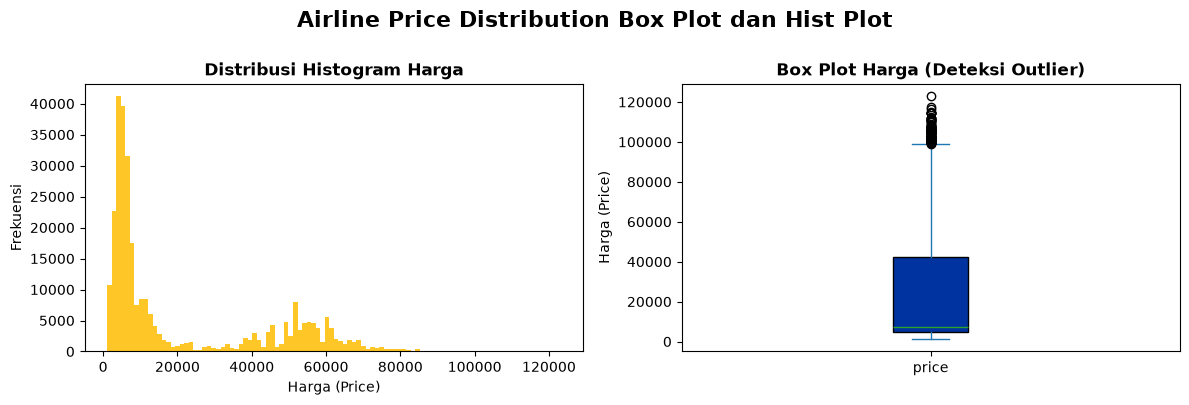

In [183]:
fig,ax = plt.subplots(1,2,figsize=(12, 4))
df['price'].plot(kind='hist',ax=ax[0], bins=100, color=['#FFC627'])
ax[0].set_title('Distribusi Histogram Harga', fontsize=12, fontweight='bold')
ax[0].set_xlabel('Harga (Price)')
ax[0].set_ylabel('Frekuensi')

df['price'].plot(kind='box',ax=ax[1],patch_artist=True, boxprops=dict(facecolor='#0033A0', color='black') )
# boxprops = dict(linestyle='-', linewidth=2, color='')

ax[1].set_title('Box Plot Harga (Deteksi Outlier)', fontsize=12, fontweight='bold')
ax[1].set_ylabel('Harga (Price)')
fig.suptitle('Airline Price Distribution Box Plot dan Hist Plot',
             y=1.00, fontsize=16, fontweight='bold', ha='center')
plt.tight_layout()
plt.show()

Diragram Right Skew karena memiliki banyak outlier

In [184]:
print(f'Duplicated Row Dataset  : {df.duplicated().sum()} \n')
print(f'Null Column Dataset : \n{df.isna().sum()}')

Duplicated Row Dataset  : 0 

Null Column Dataset : 
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64


In [185]:

for i in ['airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class']:
  print(f'Value Count {i} : {df[i].value_counts().count()}\n')

Value Count airline : 6

Value Count flight : 1561

Value Count source_city : 6

Value Count departure_time : 6

Value Count stops : 3

Value Count arrival_time : 6

Value Count destination_city : 6

Value Count class : 2



In [186]:
for i in ['airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class']:
       print(f"cols {i} : {df[i].unique()}\n")

cols airline : <StringArray>
['SpiceJet', 'AirAsia', 'Vistara', 'GO_FIRST', 'Indigo', 'Air_India']
Length: 6, dtype: str

cols flight : <StringArray>
['SG-8709', 'SG-8157',  'I5-764',  'UK-995',  'UK-963',  'UK-945',  'UK-927',
  'UK-951',  'G8-334',  'G8-336',
 ...
  '6E-804', '6E-7183', 'SG-6017', '6E-7208', '6E-7252', '6E-7141',  '6E-557',
 '6E-7127', '6E-7259',  'AI-433']
Length: 1561, dtype: str

cols source_city : <StringArray>
['Delhi', 'Mumbai', 'Bangalore', 'Kolkata', 'Hyderabad', 'Chennai']
Length: 6, dtype: str

cols departure_time : <StringArray>
['Evening', 'Early_Morning', 'Morning', 'Afternoon', 'Night', 'Late_Night']
Length: 6, dtype: str

cols stops : <StringArray>
['zero', 'one', 'two_or_more']
Length: 3, dtype: str

cols arrival_time : <StringArray>
['Night', 'Morning', 'Early_Morning', 'Afternoon', 'Evening', 'Late_Night']
Length: 6, dtype: str

cols destination_city : <StringArray>
['Mumbai', 'Bangalore', 'Kolkata', 'Hyderabad', 'Chennai', 'Delhi']
Length: 6, dtype

In [187]:
X = df.drop(columns='price')
y = df['price']

print(f"Row and Columns X : {X.shape}")
print(f"Row and Columns y : {y.shape}")

Row and Columns X : (300153, 10)
Row and Columns y : (300153,)


In [188]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42 , stratify=X['class'])

In [215]:
print(X_train.columns, X_test.columns)

Index(['class', 'duration', 'days_left', 'airline_AirAsia',
       'airline_Air_India', 'airline_GO_FIRST', 'airline_Indigo',
       'airline_SpiceJet', 'airline_Vistara', 'source_city_Bangalore',
       'source_city_Chennai', 'source_city_Delhi', 'source_city_Hyderabad',
       'source_city_Kolkata', 'source_city_Mumbai', 'departure_time_Afternoon',
       'departure_time_Early_Morning', 'departure_time_Evening',
       'departure_time_Late_Night', 'departure_time_Morning',
       'departure_time_Night', 'stops_one', 'stops_two_or_more', 'stops_zero',
       'arrival_time_Afternoon', 'arrival_time_Early_Morning',
       'arrival_time_Evening', 'arrival_time_Late_Night',
       'arrival_time_Morning', 'arrival_time_Night',
       'destination_city_Bangalore', 'destination_city_Chennai',
       'destination_city_Delhi', 'destination_city_Hyderabad',
       'destination_city_Kolkata', 'destination_city_Mumbai'],
      dtype='str') Index(['class', 'duration', 'days_left', 'airline_AirAsia

In [190]:
print('\nRaw Data proportion :')
print(df['class'].value_counts(normalize=True) * 100)
print('\nX_Train proportion :')
print(X_train['class'].value_counts(normalize=True) * 100)
print('\nX_test proportion :')
print(X_test['class'].value_counts(normalize=True) * 100)


Raw Data proportion :
class
Economy     68.853551
Business    31.146449
Name: proportion, dtype: float64

X_Train proportion :
class
Economy     68.853749
Business    31.146251
Name: proportion, dtype: float64

X_test proportion :
class
Economy     68.852759
Business    31.147241
Name: proportion, dtype: float64


# EDA

/var/folders/vv/_hxrb3z94rn17vzw2lxf_drc0000gn/T/ipykernel_18462/4156346862.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  X_train_cat = X_train.select_dtypes(include='object')


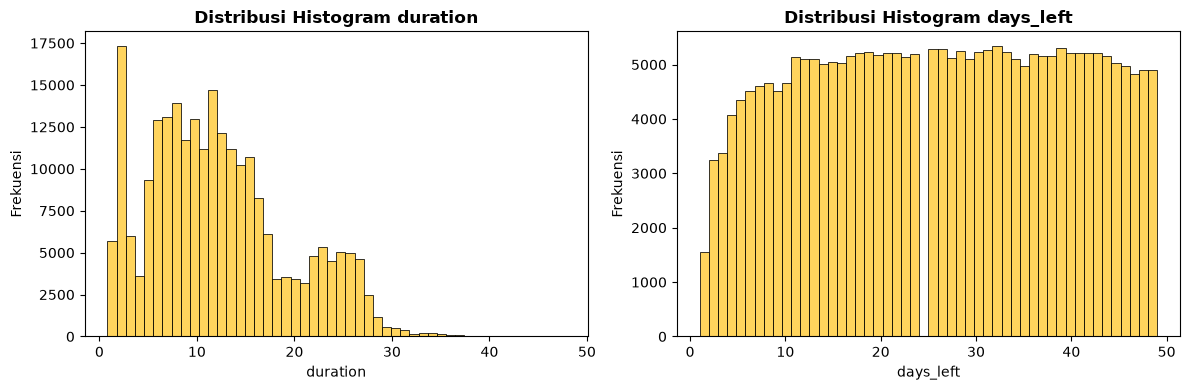

In [191]:
X_train_num = X_train.select_dtypes(include='number')
X_train_cat = X_train.select_dtypes(include='object')


num_cols = len(X_train_num.columns)

n_cols_grid = 2
n_rows_grid = (num_cols + n_cols_grid - 1) // n_cols_grid

fig, ax = plt.subplots(n_rows_grid, n_cols_grid, figsize=(12, 4 * n_rows_grid))

ax_flat = ax.flatten() if num_cols > 1 else [ax]

for i, cols in enumerate(X_train_num.columns):
    sns.histplot(data=X_train_num, x=cols, ax=ax_flat[i], bins=50,color='#FFC627')
    ax_flat[i].set_title(f'Distribusi Histogram {cols}', fontsize=12, fontweight='bold')
    ax_flat[i].set_xlabel(cols)
    ax_flat[i].set_ylabel('Frekuensi')

for j in range(i + 1, len(ax_flat)):
    fig.delaxes(ax_flat[j])

plt.tight_layout()
plt.show()

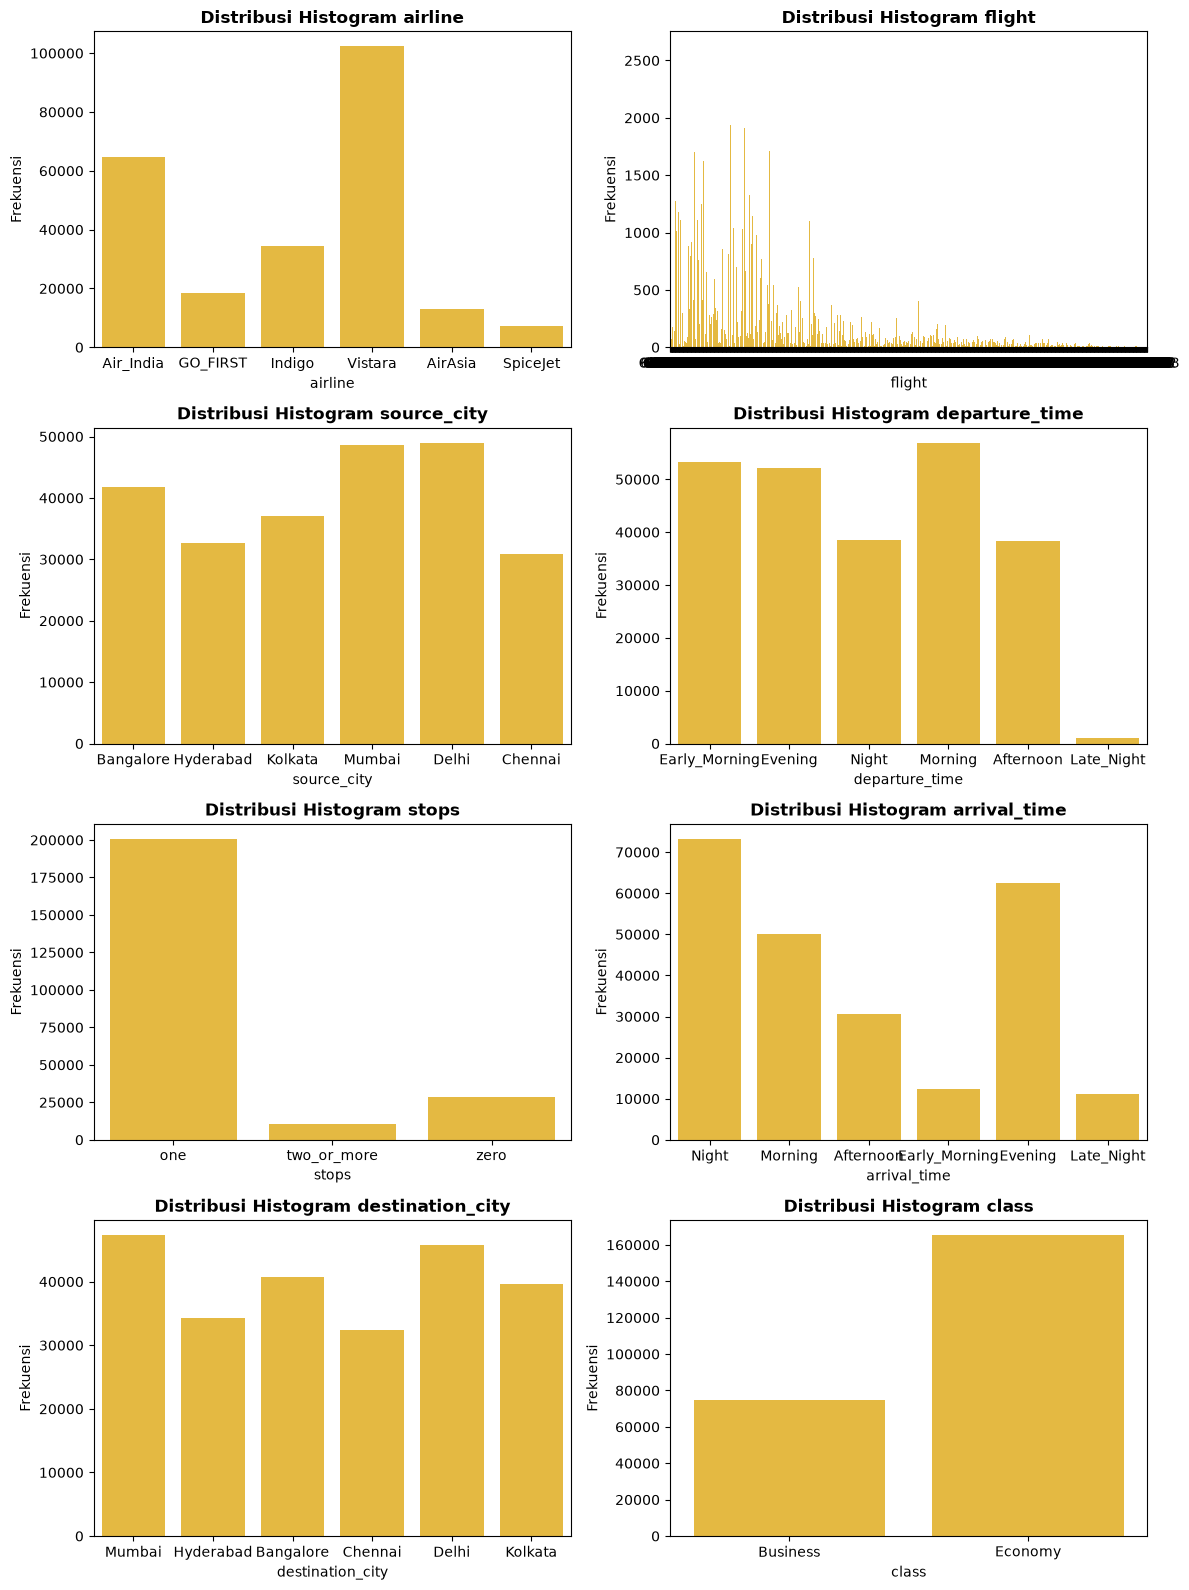

In [192]:
num_cols = len(X_train_cat.columns)

n_cols_grid = 2
n_rows_grid = (num_cols + n_cols_grid - 1) // n_cols_grid

fig, ax = plt.subplots(n_rows_grid, n_cols_grid, figsize=(12, 4 * n_rows_grid))

ax_flat = ax.flatten() if num_cols > 1 else [ax]

for i, cols in enumerate(X_train_cat.columns):
    sns.countplot(data=X_train_cat, x=cols, ax=ax_flat[i],color='#FFC627')
    ax_flat[i].set_title(f'Distribusi Histogram {cols}', fontsize=12, fontweight='bold')
    ax_flat[i].set_xlabel(cols)
    ax_flat[i].set_ylabel('Frekuensi')

for j in range(i + 1, len(ax_flat)):
    fig.delaxes(ax_flat[j])

plt.tight_layout()
plt.show()

/var/folders/vv/_hxrb3z94rn17vzw2lxf_drc0000gn/T/ipykernel_18462/2379764164.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  X_train_cat = X_train.select_dtypes(include='object')


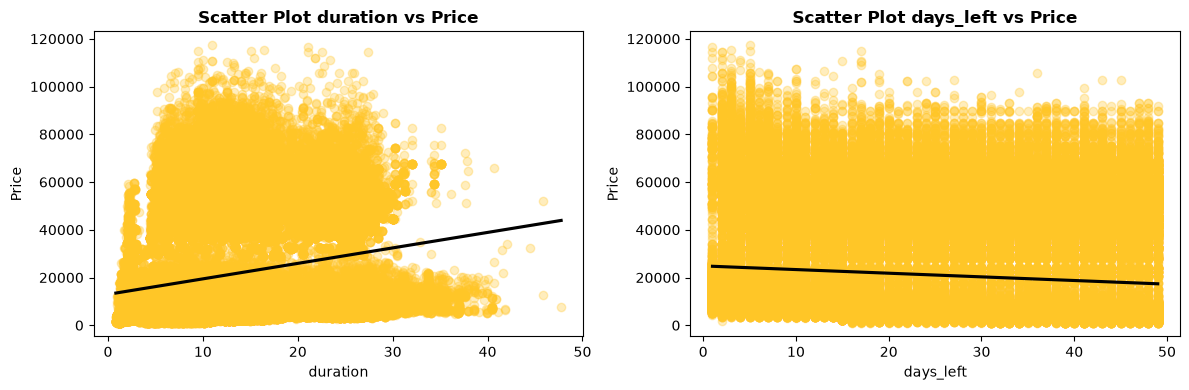

In [193]:
X_train = X_train.drop(columns='flight')
X_test = X_test.drop(columns='flight')

X_train_num = X_train.select_dtypes(include='number')
X_train_cat = X_train.select_dtypes(include='object')


num_cols = len(X_train_num.columns)

n_cols_grid = 2
n_rows_grid = (num_cols + n_cols_grid - 1) // n_cols_grid

fig, ax = plt.subplots(n_rows_grid, n_cols_grid, figsize=(12, 4 * n_rows_grid))

ax_flat = ax.flatten() if num_cols > 1 else [ax]

for i, cols in enumerate(X_train_num.columns):
    sns.regplot(data=X_train_num, x=cols,y= y_train, ax=ax_flat[i],color='#FFC627', line_kws={'color': 'black'},scatter_kws={'alpha': 0.3})
    ax_flat[i].set_xlabel(cols)
    ax_flat[i].set_ylabel('Price')
    ax_flat[i].set_title(f'Scatter Plot {cols} vs Price', fontsize=12, fontweight='bold')

for j in range(i + 1, len(ax_flat)):
    fig.delaxes(ax_flat[j])

plt.tight_layout()
plt.show()

- hubungan duration dan price kuat (positive), Semakin lama durasinya semakin naik harganya
- hubungan secara linear antara days_left dan price lemah

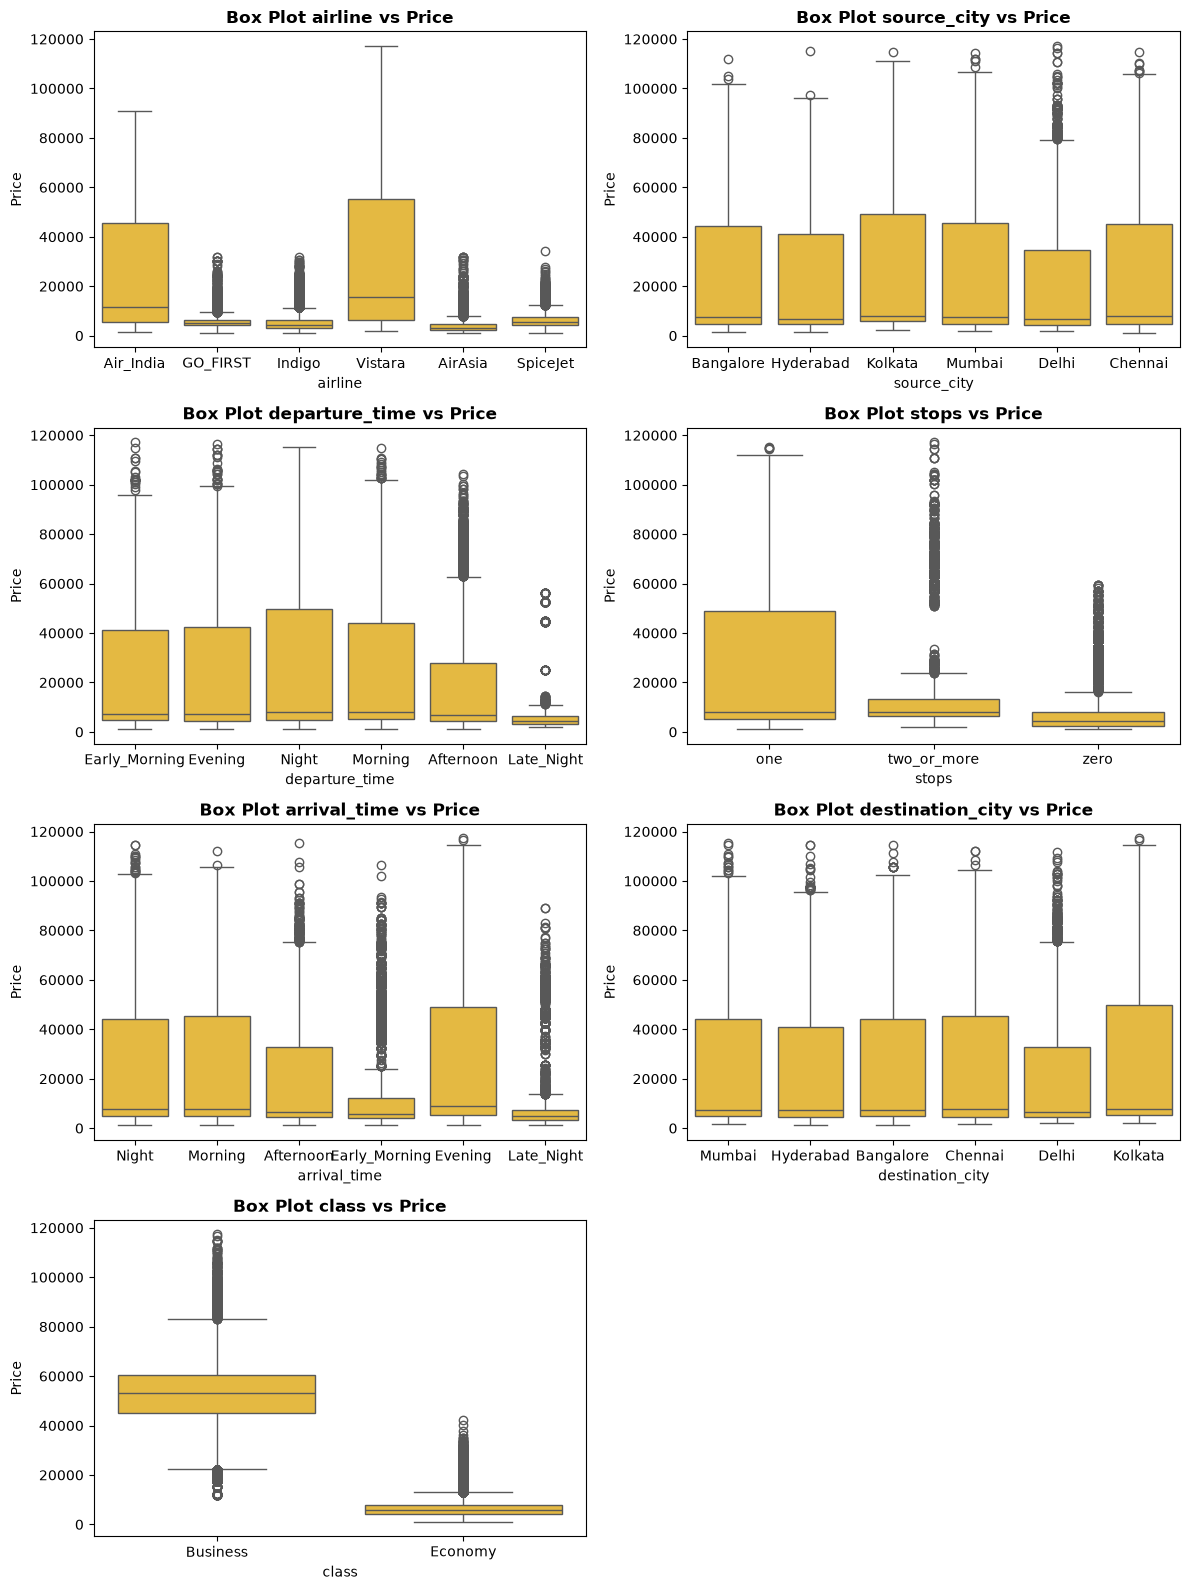

In [194]:
num_cols = len(X_train_cat.columns)

n_cols_grid = 2
n_rows_grid = (num_cols + n_cols_grid - 1) // n_cols_grid

fig, ax = plt.subplots(n_rows_grid, n_cols_grid, figsize=(12, 4 * n_rows_grid))

ax_flat = ax.flatten() if num_cols > 1 else [ax]

for i, cols in enumerate(X_train_cat.columns):
    sns.boxplot(data=X_train_cat, x=cols, y=y_train, ax=ax_flat[i],color='#FFC627')
    ax_flat[i].set_title(f'Box Plot {cols} vs Price', fontsize=12, fontweight='bold')
    ax_flat[i].set_xlabel(cols)
    ax_flat[i].set_ylabel('Price')

for j in range(i + 1, len(ax_flat)):
    fig.delaxes(ax_flat[j])

plt.tight_layout()
plt.show()

- airline, class, stops punya pengaruh kuat terhadap price

#Preprocesing

In [195]:
label_encoding = []
count_label_encoding = 0

one_hot_encoding = []
count_one_hot_encoding = 0

for i in X_train.columns:
  if X_train[i].dtypes == 'str' or X_train[i].dtype == 'object' :
    if X_train[i].nunique()<=2 :
      label_encoding.append(i)
      count_label_encoding += 1
    else:
      one_hot_encoding.append(i)
      count_one_hot_encoding += 1


print(f'Cols to OneHotEncoding {count_label_encoding} :\n{X_train[label_encoding].nunique()}\n')
print(f'Cols to OneHotEncoding {count_one_hot_encoding} :\n{X_train[one_hot_encoding].nunique()}\n')

Cols to OneHotEncoding 1 :
class    2
dtype: int64

Cols to OneHotEncoding 6 :
airline             6
source_city         6
departure_time      6
stops               3
arrival_time        6
destination_city    6
dtype: int64



In [196]:
print(label_encoding)
print(one_hot_encoding)

['class']
['airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city']


In [197]:
# from sklearn.preprocessing import LabelEncoder,OneHotEncoder

# le = LabelEncoder()
# for i in label_encoding:
#   X_train[i] = le.fit_transform(X_train[i])
#   X_test[i] = le.transform(X_test[i])


# for i in one_hot_encoding:
#   ohe = OneHotEncoder(sparse_output=False)
#   ohe_train = ohe.fit_transform(X_train[[i]])
#   ohe_test = ohe.transform(X_test[[i]])

#   train_enc_df = pd.DataFrame(ohe_train, columns=ohe.get_feature_names_out([i]), index=X_train.index)
#   test_enc_df = pd.DataFrame(ohe_test, columns=ohe.get_feature_names_out([i]), index=X_test.index)
#   print(ohe.get_feature_names_out([i]))
#   X_train = pd.concat([X_train.drop(columns=[i]), train_enc_df], axis=1)
#   X_test = pd.concat([X_test.drop(columns=[i]), test_enc_df], axis=1)



from sklearn.preprocessing import LabelEncoder, OneHotEncoder

le_dict = {}
ohe_dict = {}

for i in label_encoding:
    le_dict[i] = LabelEncoder()
    X_train[i] = le_dict[i].fit_transform(X_train[i])
    X_test[i] = le_dict[i].transform(X_test[i])

for i in one_hot_encoding:
    ohe_dict[i] = OneHotEncoder(sparse_output=False)
    ohe_train = ohe_dict[i].fit_transform(X_train[[i]])
    ohe_test = ohe_dict[i].transform(X_test[[i]])

    train_enc_df = pd.DataFrame(ohe_train, columns=ohe_dict[i].get_feature_names_out([i]), index=X_train.index)
    test_enc_df = pd.DataFrame(ohe_test, columns=ohe_dict[i].get_feature_names_out([i]), index=X_test.index)

    X_train = pd.concat([X_train.drop(columns=[i]), train_enc_df], axis=1)
    X_test = pd.concat([X_test.drop(columns=[i]), test_enc_df], axis=1)


In [198]:
print(le_dict)
print(ohe_dict)
print("Ukuran X_train sekarang:", X_train.shape)


{'class': LabelEncoder()}
{'airline': OneHotEncoder(sparse_output=False), 'source_city': OneHotEncoder(sparse_output=False), 'departure_time': OneHotEncoder(sparse_output=False), 'stops': OneHotEncoder(sparse_output=False), 'arrival_time': OneHotEncoder(sparse_output=False), 'destination_city': OneHotEncoder(sparse_output=False)}
Ukuran X_train sekarang: (240122, 36)


In [199]:
X_train.head()

,class,duration,days_left,airline_AirAsia,airline_Air_India,airline_GO_FIRST,airline_Indigo,airline_SpiceJet,airline_Vistara,source_city_Bangalore,...,arrival_time_Evening,arrival_time_Late_Night,arrival_time_Morning,arrival_time_Night,destination_city_Bangalore,destination_city_Chennai,destination_city_Delhi,destination_city_Hyderabad,destination_city_Kolkata,destination_city_Mumbai
index,,,,,,,,,,,,,,,,,,,,,
249451,0,16.00,11,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
110868,1,6.25,12,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
168963,1,10.33,34,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
149799,1,5.33,21,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
83543,1,11.17,45,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0


In [200]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scale = pd.DataFrame(scaler.fit_transform(X_train),columns=X_train.columns, index=X_train.index)
X_test_scale = pd.DataFrame(scaler.transform(X_test),columns=X_test.columns, index=X_test.index)


print(f'Std X_train_scale : \n{X_train_scale.std().mean():.6f}\n \n')
print(f'Mean X_train_scale : \n{X_train_scale.mean().mean():.6f}\n \n')


Std X_train_scale : 
1.000002
 

Mean X_train_scale : 
0.000000
 



In [201]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.tree import DecisionTreeRegressor

models = [
    ('Linear Regression', LinearRegression()),
    ('Ridge Regression', Ridge()),
    ('Decision Tree Regressor', DecisionTreeRegressor(random_state=42)),
    ('Random Forest', RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=5,
        max_features=0.5,
        random_state=42,
        n_jobs=-1)),
    ('Gradient Boosting', GradientBoostingRegressor(random_state=42))
]
result = []


for name, model in models :
  model.fit(X_train_scale, y_train)
  y_pred = model.predict(X_test_scale)
  result.append({
      'Model' : name,
      'MAE' : mean_absolute_error(y_test,y_pred),
      'R2' : r2_score(y_test,y_pred)
  }
  )

In [202]:
result_= pd.DataFrame(result).sort_values(by='R2',ascending=False)
print(result_.to_string(index=False))

                  Model         MAE       R2
          Random Forest 1249.463086 0.985580
Decision Tree Regressor 1154.499398 0.976606
      Gradient Boosting 2961.366641 0.951959
      Linear Regression 4588.222442 0.910762
       Ridge Regression 4588.224923 0.910762


**Random Forest** Model plg baik dengan MSE dan MAE terendah dan r2 score plg mendekati 1

**Linear Regresion** Model paling jelek dengan MSE dan MAE tertinggi dan R2 score yang plg jauh dari 1

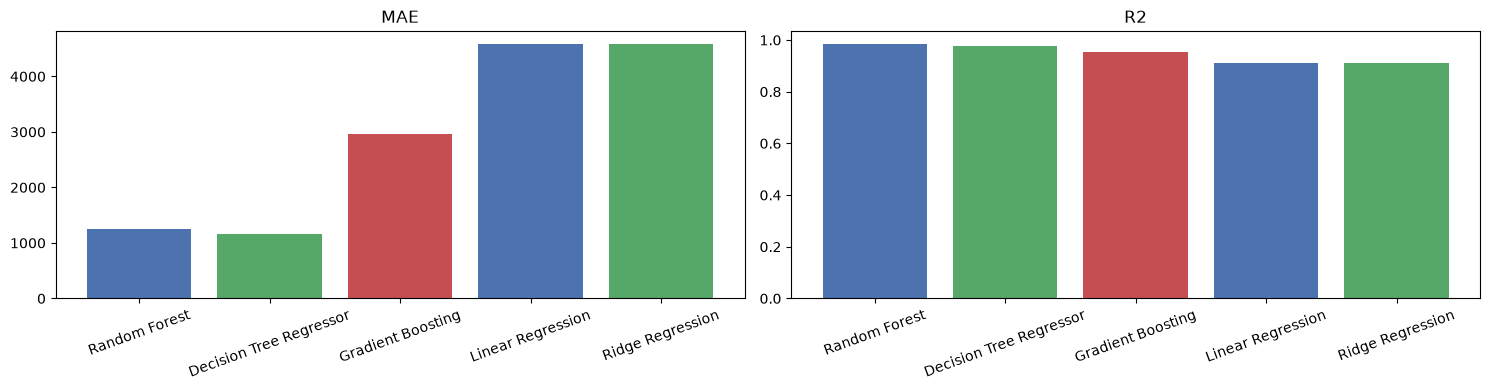

In [203]:

fig, axes = plt.subplots(1, 2, figsize=(15, 4))

for ax, metric in zip(axes, ['MAE', 'R2']):
    ax.bar(result_['Model'], result_[metric], color=['#4C72B0', '#55A868', '#C44E52'])
    ax.set_title(metric)
    ax.tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()


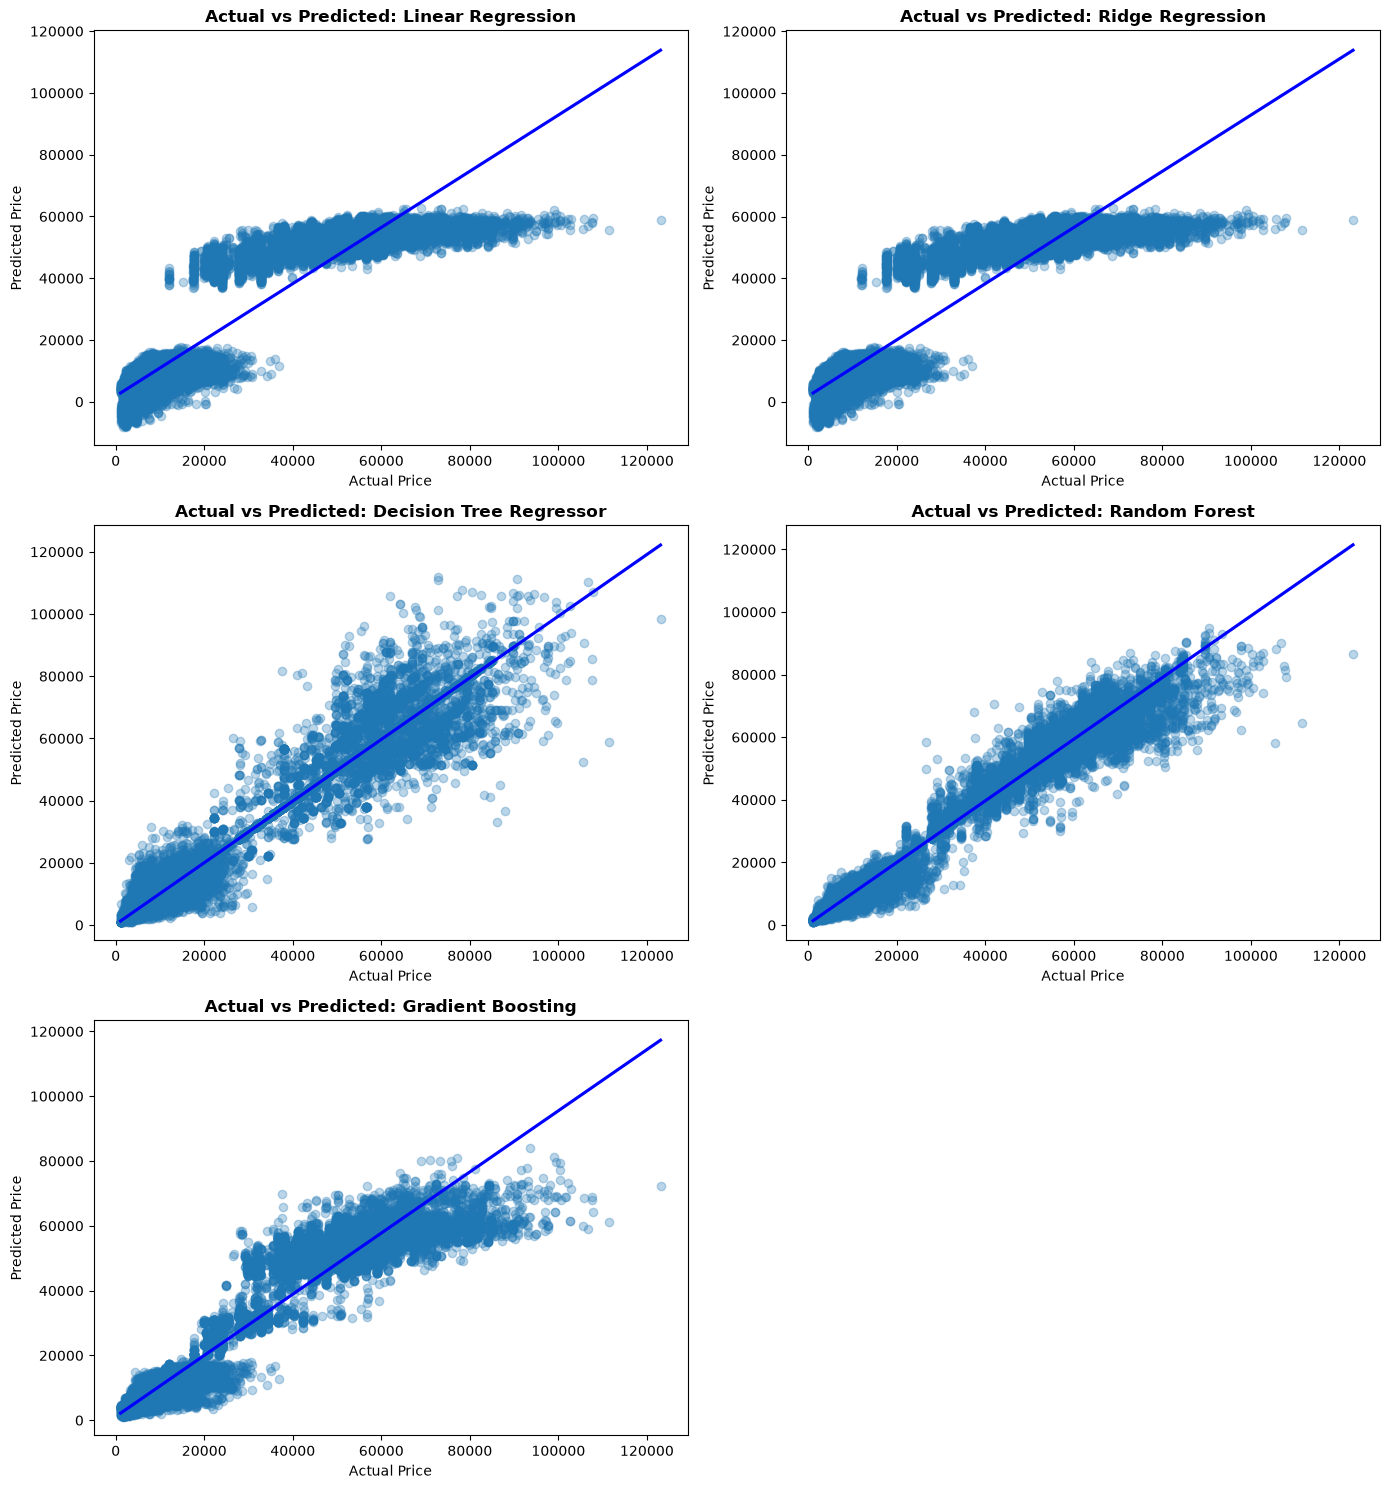

In [204]:
n_cols_grid = 2
num_models = len(models)
n_rows_grid = (num_models + n_cols_grid - 1) // n_cols_grid

fig, axes = plt.subplots(ncols=n_cols_grid, nrows=n_rows_grid, figsize=(14, 5 * n_rows_grid))

axes = axes.flatten()

for ax, (name, model) in zip(axes, models):
    y_pred = model.predict(X_test_scale)
    
    sns.regplot(x=y_test, y=y_pred, ax=ax, scatter_kws={'alpha': 0.3}, line_kws={'color': 'blue'})

    ax.set_title(f'Actual vs Predicted: {name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Actual Price', fontsize=10)
    ax.set_ylabel('Predicted Price', fontsize=10)

for j in range(num_models, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Visualisasi perbandingan tebakan dengan nilai asli



In [205]:
for name, model in models:
  r2_train = r2_score(y_train, model.predict(X_train_scale))
  r2_test = r2_score(y_test, model.predict(X_test_scale))

  mae_train = mean_absolute_error(y_train, model.predict(X_train_scale))
  mae_test = mean_absolute_error(y_test, model.predict(X_test_scale))

  print(f"{name} R2 : {r2_train} | {r2_test}")
  print(f"{name} MAE : {mae_train} | {mae_test}")
  print()

Linear Regression R2 : 0.9116271798834923 | 0.9107621771065719
Linear Regression MAE : 4560.098607681853 | 4588.222441794262

Ridge Regression R2 : 0.9116271798647064 | 0.9107621629641514
Ridge Regression MAE : 4560.100436668273 | 4588.224922740911

Decision Tree Regressor R2 : 0.9993073446492559 | 0.9766057555334706
Decision Tree Regressor MAE : 56.98162045404697 | 1154.4993975334967

Random Forest R2 : 0.9897415139621618 | 0.9855803147309781
Random Forest MAE : 1042.6508192885203 | 1249.4630859490303

Gradient Boosting R2 : 0.9524779061464543 | 0.9519586314508817
Gradient Boosting MAE : 2937.02218439226 | 2961.366641255638



Pengecekan Overfit/ underfit :
dapat di lihat bahawa hasil r2 score tiap model selisihnya tidak jauh sama sama tinggi (ada overfit pada bagian random forest tapi cuma sedikit jadi masih aman)

In [206]:
print(RandomForestRegressor().get_params())

{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': None, 'verbose': 0, 'warm_start': False}


In [207]:
from sklearn.model_selection import RandomizedSearchCV
param = {
    'n_estimators' :[100,200,300] ,
    'max_features': ['sqrt',0.5,1.0] ,
    'min_samples_leaf':[1,2,5],
    'max_depth': [10,20,None]

}

search = RandomizedSearchCV(
    estimator = RandomForestRegressor(random_state=42, n_jobs=1),
    param_distributions = param,
    cv=3,
    verbose=2,
    scoring='r2',
    n_iter=8,
    random_state=42
)

search.fit(X_train_scale,y_train)

print(f'Best Score : {search.best_score_}')
print(f'Best Params : {search.best_params_}')



Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=2, n_estimators=100; total time=   7.2s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=2, n_estimators=100; total time=   7.0s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=2, n_estimators=100; total time=   7.1s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, n_estimators=100; total time=   3.8s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, n_estimators=100; total time=   3.9s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, n_estimators=100; total time=   3.8s
[CV] END max_depth=10, max_features=1.0, min_samples_leaf=2, n_estimators=200; total time=  32.7s
[CV] END max_depth=10, max_features=1.0, min_samples_leaf=2, n_estimators=200; total time=  33.2s
[CV] END max_depth=10, max_features=1.0, min_samples_leaf=2, n_estimators=200; total time=  32.4s
[CV] END max_depth=20, max_features=sqrt, min_sample

In [208]:
rf_best_model = search.best_estimator_

y_pred_after_tuning = rf_best_model.predict(X_test_scale)

print(f'R2 : {r2_score(y_test,y_pred_after_tuning)}')
print(f'MAE : {mean_absolute_error(y_test,y_pred_after_tuning)}')

R2 : 0.9856012143909978
MAE : 1248.7743407073503


Hasil sebelum Finetuning : 0.985240094463211

Hasil sesudah Finetuning : 0.9856011298748192


Karena hasil perubahan kecil jadi Random Forest Default yang akan di pakai

In [209]:
rf_default_model = dict(models)['Random Forest']
print(rf_default_model)

RandomForestRegressor(max_features=0.5, min_samples_leaf=5, n_jobs=-1,
                      random_state=42)


In [210]:
importance = pd.DataFrame({
    'Feature': X_train_scale.columns,
    'Importance': rf_default_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print(importance.sort_values(by='Importance'))

                         Feature  Importance
18     departure_time_Late_Night    0.000053
27       arrival_time_Late_Night    0.000149
7               airline_SpiceJet    0.000543
28          arrival_time_Morning    0.000622
20          departure_time_Night    0.000679
24        arrival_time_Afternoon    0.000768
16  departure_time_Early_Morning    0.000793
15      departure_time_Afternoon    0.000804
25    arrival_time_Early_Morning    0.000834
19        departure_time_Morning    0.000845
31      destination_city_Chennai    0.000901
10           source_city_Chennai    0.000921
17        departure_time_Evening    0.001083
29            arrival_time_Night    0.001122
26          arrival_time_Evening    0.001143
9          source_city_Bangalore    0.001282
12         source_city_Hyderabad    0.001310
30    destination_city_Bangalore    0.001384
33    destination_city_Hyderabad    0.001449
22             stops_two_or_more    0.001669
14            source_city_Mumbai    0.001745
13        

In [211]:
print(importance.head(10))

              Feature  Importance
0               class    0.825823
8     airline_Vistara    0.041885
1            duration    0.039509
2           days_left    0.014337
4   airline_Air_India    0.011220
23         stops_zero    0.010819
6      airline_Indigo    0.010453
21          stops_one    0.007864
5    airline_GO_FIRST    0.004057
11  source_city_Delhi    0.003189


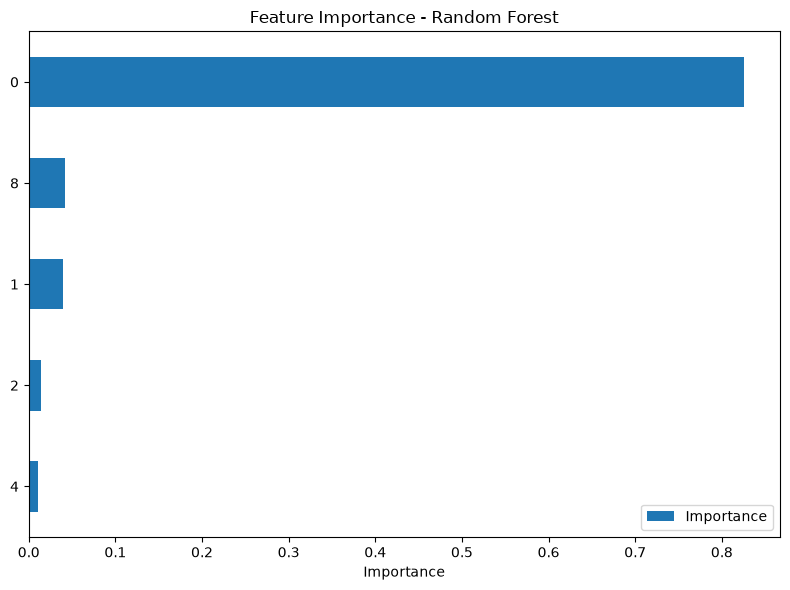

In [212]:
importance.sort_values(by='Importance', ascending=True).tail().plot(kind='barh', figsize=(8, 6))
plt.title('Feature Importance - Random Forest')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

In [213]:
import sklearn
print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.9.0


In [221]:
feature = X_train_scale.columns.to_list()
print(len(feature))

36


In [222]:
import joblib
joblib.dump(rf_default_model, 'rf_default_model.pkl')
joblib.dump(le_dict, 'le_dict.pkl')
joblib.dump(ohe_dict, 'ohe_dict.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(feature, 'feature.pkl')

['feature.pkl']